# Evidence Before Execution

## A local mathematical and policy boundary for developer-agent proposals

Technical artifact paper. This is a reproducible submission candidate, not an accepted publication or a report of Gemma inference.

## Abstract

Developer agents can produce convincing explanations for incorrect arithmetic and unsafe operational actions. A language-model critique does not establish that either is safe. This work separates proposal generation from approval using two independently inspectable layers. MuseWeaver checks a restricted transition specification with Z3. BlastRadius Zero checks a closed action schema against deterministic resource, privilege and offline-egress policies. The combined boundary accepts only when both checks succeed. A factorial control experiment crosses four arithmetic candidates with ten labelled actions and repeats the forty distinct combinations twelve times for runtime measurement. The combined boundary rejects all 420 unsafe repeated cases while accepting all 60 safe repeated cases. Formal verification alone and policy verification alone leave different classes of unsafe proposals admissible. A separate probe deliberately documents weaknesses of heuristic text scanning. The artifact includes executable source, raw decisions, counterexamples, source hashes, a paper notebook and an optional loopback-only model adapter. The experiment measures a model-independent verification boundary; it does not evaluate Gemma 4 generation quality, natural attack prevalence or arbitrary program correctness.

## 1. Motivation and research question

A developer agent commonly has two responsibilities that are easy to conflate. It proposes an implementation and it requests operational capabilities. Even a correct implementation can be paired with an unsafe deployment action. Conversely, a permitted test command can carry a mathematically incorrect candidate. Asking a second model to review the first model's answer leaves both responsibilities in a probabilistic trust domain.

The research question is whether a small, free local boundary can make these responsibilities separately executable and inspectable. The contribution is an artifact and a controlled composition experiment, not a new SMT algorithm or a claim of complete autonomous-agent security.

The practical design goal is a narrow approval interface. A proposer produces a JSON envelope with exactly a mathematical proposal and an action manifest. Neither layer treats an explanation, an assertion written by the proposer or a clean-looking text snippet as authority. Approval does not execute the action. An executor must preserve the same restrictions if subsequently connected.

## 2. System architecture

The implemented boundary is

```text
structured agent envelope
  -> MuseWeaver mathematical verifier
  -> BlastRadius Zero typed policy gate
  -> combined approval or denial
  -> separately controlled executor, not included
```

The mathematical and policy layers are the actual modules from the flagship repositories. The research bundle includes byte-identical snapshots and a source manifest. In the campaign workspace the benchmark can resolve those live modules; in a standalone checkout it resolves the bundled snapshots. Reproduction records source hashes so readers can distinguish the measured implementation from an earlier repository commit.

`agent_boundary.py` exposes the composed runtime interface. `local_agent_adapter.py` can query an already served local OpenAI-compatible model using a fixed nonpersonal demonstration prompt. It permits exact loopback hosts, disables proxies and redirects, and applies the same approval function to the returned envelope. The model adapter was contract-tested with a local mock response. No actual Gemma model was downloaded or queried in the reported experiment.

BlastRadius Zero additionally supplies a Bedrock function-action-group handler. Its Lambda response contract is tested without AWS credentials. This is an integration adapter, not evidence of a deployed Bedrock agent or cloud workload.

## 3. Mathematical verification

### 3.1 Exact integer token transitions

Let capacity be C positive tokens, unit scale U = 1,000,000, balance b in integer microtokens and refill increment delta an arbitrary nonnegative integer. The reference transition computes

```text
refilled = min(C * U, b + delta)
admitted = refilled >= U
after = refilled - U if admitted else refilled
```

The precondition is `C >= 1`, `0 <= b <= C*U` and `delta >= 0`. The verifier negates the conjunction of nonnegative post-balance, capacity bound, exact admission agreement and exact post-state agreement. Z3 returning unsatisfiable means no violating assignment exists in this unbounded integer transition model.

Using delta rather than a floating-point elapsed-time product makes the proof scope explicit. A runtime implementation must calculate refill in compatible units and obey the monotonic-time precondition. The JavaScript bucket uses BigInt intermediates before saturation and rejects inexact or invalid control values. A 5,000-transition independent integer-oracle regression checks the implemented behavior, but it is not a compiler-checked correspondence proof.

The candidate DSL exposes clamping, debit amount and inclusive admission. Removing clamping, changing debit by one microtoken and using a strict admission comparison create actual satisfiable counterexamples. Unsupported candidate languages and malformed schemas cannot produce a certificate. Solver `unknown` is not acceptance.

### 3.2 Quorum safety and availability

For two quorums of size q from N members, the intersection lower bound is `2q-N`. With at most f Byzantine members, an honest intersection requires `2q-N > f`. Availability under up to f unavailable members additionally requires `q <= N-f`.

The demonstration intentionally includes a configuration whose intersection is safe but whose quorum cannot remain available. This avoids presenting a large threshold as a complete distributed-systems proof. The model does not encode a full consensus protocol, message delivery, authentication or an adversarial scheduler.

## 4. Deterministic operational policy

A manifest has a version, a supported kind and exactly that kind's permitted parameters. The gate checks canonical virtual workspace paths, explicit test argument vectors, preview-only deletion, limited read-only IAM permissions and bounded compute descriptions. Cost is calculated per replica in integer cents. Network actions are always denied by the default offline policy.

These checks authorize descriptions. They do not establish filesystem isolation, resolve actual symlinks or enforce a host firewall. In particular, a downstream executor must not reinterpret a path as a shell fragment, broaden an approved resource scope or silently grant capabilities after denial.

A separate browser text scanner remains useful for diagnostic explanations, but it is explicitly heuristic. The benchmark's text probe includes an obfuscated destructive statement that the scanner misses and a quoted documentation string that it flags incorrectly. This prevents the typed enforcement result from being misrepresented as perfect understanding of arbitrary shell or SQL.

## 5. Experimental method

The control set contains ten action fixtures. Five are permitted read, test, cost-boundary, deletion-preview and read-only IAM descriptions. Five are denied traversal, actual deletion, cost overrun, wildcard privilege and offline-exfiltration descriptions. Their expected labels are specified in the fixture generator rather than inferred by invoking the measured gate.

Each action is crossed with four arithmetic candidates. One implements the reference transition; three contain a targeted mutant. A combination is safe only when both its mathematical candidate and operational action are safe. This produces five safe and thirty-five unsafe distinct combinations.

Twelve repetitions yield 480 measured requests, comprising 60 safe and 420 unsafe repeated cases. Repetitions measure local checking overhead. They are not 480 independent real-world attacks, model outputs or human trials. No binomial confidence interval for natural attack success is inferred from this deliberately constructed factorial set.

Four ablations execute the actual local code. No guard admits every candidate. Formal-only applies Z3 but not the operational gate. Policy-only applies the operational gate but not Z3. Combined applies both. Each row records safe acceptance, unsafe rejection, unsafe acceptance, false rejection and measured median, p95 and aggregate checking time.

Timers use the process performance counter. Mathematical checking includes solver construction and satisfiability checking. The scanner probe is separate and does not inflate the typed-boundary detection score. Runtime numbers are specific to the recorded Python, solver, operating system and architecture.

## 6. Results and interpretation

The combined boundary accepts the 60 repeated safe cases and rejects all 420 repeated unsafe cases. Formal-only rejects the 360 cases containing an arithmetic mutant but admits the 60 cases with a correct transition and an unsafe action. Policy-only rejects 240 cases with a denied action but admits 180 mathematically incorrect candidates paired with a permitted action.

The difference is expected from the factorial construction and demonstrates correct composition of two distinct contracts. It is not evidence that the boundary would reject every naturally occurring malicious agent behavior. Adding another permitted action class, mathematical language or external tool would expand the proof and policy obligations.

The raw ledger makes the result auditable. Readers can examine each mode, labelled case, actual solver status, integer counterexample and gate rule. Runtime tables are generated directly from that ledger. There are no estimated speedups, smoothed detection curves or hand-entered timing results.

The heuristic scanner probe is intentionally less successful. Its errors show why diagnostics cannot be the sole capability boundary. A model might exploit syntax not represented by the scanner, or benign documentation might be blocked. The typed gate avoids relying on that interpretation by accepting only its specified action language.

## 7. Security scope and limitations

The transition DSL is deliberately small. It does not prove arbitrary source programs, concurrency, database migrations, total correctness or termination. The correspondence between the model and JavaScript implementation is tested and inspected rather than automatically proved by a verified compiler.

Custom browser execution uses an opaque-origin frame and a timed worker with network-denying CSP. That mechanism is tested separately. Self-reported assertions are not proof, and browser compromise or memory exhaustion is not ruled out.

The policy module is not an executor. A process that bypasses it can still make unsafe changes. An integrated agent must place approval at the actual capability boundary, preserve request identity and ensure that the bytes checked are the bytes executed. The current artifact hashes manifests but does not implement a production distributed authorization protocol.

The benchmark contains generated mutants, not Gemma outputs. No conclusion about Gemma 4, Muse Spark or another model's reliability follows. There is no cloud-performance measurement, deployment-scale evaluation, human-subject study or claim of competition eligibility.

## 8. Reproducibility and ethical disclosure

All measured source is local and inspectable. The package pins dependencies, records source digests and includes an executable notebook that reruns the experiment in a temporary results directory. Neither the benchmark nor its synthetic fixtures requires a vendor key, external inference service or personal information.

The optional model connector uses a fixed nonpersonal prompt. Real deployment with private source needs its own data-handling review. Public reports should never include actual credentials or private pasted plans.

No original student narrative, human testing network, Kiro usage log, tracked work time, partnership or award is invented. The Gemma competition page title has been checked, but venue-specific eligibility and model-use requirements must be satisfied before this artifact is entered.

## 9. Conclusion

A small mathematical language and a closed operational schema can provide a free, reproducible boundary around developer-agent proposals. The controlled experiment confirms that the two layers reject complementary failure classes and compose as intended. The principal result is executable evidence with precise scope. Extending the system responsibly requires new verification obligations and actual model, executor and deployment evaluation rather than broader claims.

## References

1. Leonardo de Moura and Nikolaj Bjorner. Z3, an efficient SMT solver. TACAS, 2008. [Publisher DOI](https://doi.org/10.1007/978-3-540-78800-3_24).
2. Z3 project. [Solver source and documentation](https://github.com/Z3Prover/z3).
3. AWS. [Lambda functions for Amazon Bedrock action groups](https://docs.aws.amazon.com/bedrock/latest/userguide/agents-lambda.html).
4. Google and Kaggle. [The Gemma 4 Good Hackathon competition page](https://www.kaggle.com/competitions/gemma-4-good-hackathon). The page title was publicly readable; full rules are not established by that title.

## Executable reproduction

The next cell reruns the actual benchmark. Only the bundled public data and synthetic fixtures are used. Install the pinned requirements first. Hardware-dependent timings may change. Unavailable GPU backends are not relabelled as CPU results.

## Recomputed empirical results

| mode | cases | safe_allowed | unsafe_rejected | unsafe_allowed | false_rejects | unsafe_rejection_rate | median_ms | p95_ms | total_ms |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| no_guard | 480 | 60 | 0 | 420 | 0 | 0.000000 | 0.000083 | 0.000084 | 0.033560 |
| formal_only | 480 | 60 | 360 | 60 | 0 | 0.857143 | 1.411688 | 1.628550 | 688.952255 |
| policy_only | 480 | 60 | 240 | 180 | 0 | 0.571429 | 0.005542 | 0.006791 | 2.891780 |
| combined | 480 | 60 | 420 | 0 | 0 | 1.000000 | 1.389604 | 1.498210 | 663.964082 |


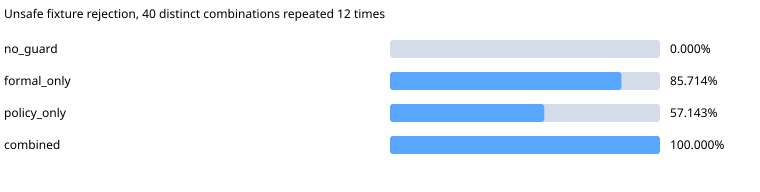

{
  "environment": {
    "system": "Darwin",
    "architecture": "arm64",
    "python": "3.13.18",
    "dependencies": {
      "numpy": "2.3.4",
      "z3-solver": "4.15.3.0",
      "cryptography": "46.0.3"
    }
  },
  "metadata": {
    "seed": 2026,
    "repetitions": 12,
    "candidate_source": "generated arithmetic mutants and labelled action fixtures",
    "gemma_inference_run": false,
    "scope": "restricted transition DSL plus structured action allowlist",
    "formal_source_sha256": "9132e0e7c10f2eeb1084c8e46deb8759a4c1c6dc3a6cf755ec5fe1d84adde3ff",
    "policy_source_sha256": "ab95435c73ec1dcaf697a461286248de5acb125fd4d922c26cb1c447df3ea2f3",
    "heuristic_scanner_probe": {
      "source_sha256": "5b00018dce5886769eb4b1fad6a40ead2e538db9c4cf5d51470770266d0a66d9",
      "cases": [
        {
          "id": "read_only",
          "unsafe": false,
          "flagged": false
        },
        {
          "id": "drop",
          "unsafe": true,
          "flagged": true
        

In [1]:
import json, os, subprocess, sys, tempfile
from pathlib import Path
from IPython.display import display, Markdown, SVG

# Run from the bundle root or the paper directory. No personal path is embedded.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "research_common.py").is_file()), None)
if ROOT is None and Path("/kaggle/input").is_dir():
    mounted = list(Path("/kaggle/input").glob("*/research_common.py"))
    mounted += list(Path("/kaggle/input").glob("*/kaggle_submissions/research_common.py"))
    if len(mounted) == 1:
        ROOT = mounted[0].parent
if ROOT is None:
    raise RuntimeError("Open this notebook within the complete research bundle")
sys.path.insert(0, str(ROOT))
from research_common import markdown_table
from publication_builder import comparison_svg

env = {**os.environ, "OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1", "VECLIB_MAXIMUM_THREADS": "1"}
with tempfile.TemporaryDirectory(prefix="research-reproduction-") as temporary:
    output = Path(temporary)
    child = subprocess.run(
        [sys.executable, str(ROOT / 'gemma-4-developer-agent-paper' / 'guardrail_benchmark.py'), "--output", str(output)],
        text=True, capture_output=True, env=env, timeout=600,
    )
    if child.returncode:
        raise RuntimeError("Benchmark failed; inspect the local command output")
    report = json.loads((output / "results.json").read_text())

assert report["schema_version"] == 1
assert report["summary"]
display(Markdown("## Recomputed empirical results\n\n" + markdown_table(report["summary"])))
if "acoustic" in report["metadata"]:
    display(Markdown("## Recomputed acoustic results\n\n" + markdown_table(report["metadata"]["acoustic"])))
display(SVG(comparison_svg('gemma-4-developer-agent-paper', report)))
print(json.dumps({"environment": report["environment"], "metadata": report["metadata"]}, indent=2))
